# Transaction Fraud Detection | Artefact Data Science Case

**Objective:** Identify potentially fraudulent transactions, compare interpretable and nonlinear classification models, and deliver January 2026 predictions.

**Workflow:** EDA → temporal validation → model comparison → threshold selection → final predictions.

The decision threshold is chosen on validation data, not on the final test set. All monetary costs, if discussed, require business confirmation.

In [1]:

from pathlib import Path


import numpy as np
import pandas as pd


import matplotlib.pyplot as plt

# Preprocessing and pipelines
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model evaluation and interpretation
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    precision_recall_curve,
    recall_score,
    roc_auc_score,
)
from sklearn.inspection import permutation_importance
from sklearn.base import clone


## 1. Exploratory Data Analysis

**Research Question:** What are the main characteristics of the transaction dataset, and how are fraudulent and legitimate transactions distributed?

This analysis examines data quality, class distribution, and transaction values to identify potential fraud patterns.

In [2]:
df = pd.read_csv("/content/transacoes_historico_2025.csv")

display(df.head())

print("Rows and columns:")
print(df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nFraud class distribution:")
print(df["flag_fraude"].value_counts())


taxa_fraude = df["flag_fraude"].mean() * 100

print(f"Fraud rate: {taxa_fraude:.2f}%")

,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,flag_fraude,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao
0,2025-01-01 00:00:00,Pharmacy Z,Pharmacy,9.12,Cliente_16621,Recife,False,desktop,False,31.5,72519-282,562,madrugada,baixo,Nordeste
1,2025-01-01 00:01:00,Supermarket A,Supermarket,37.74,Cliente_12596,Recife,False,mobile,False,28.1,43549-179,461,madrugada,medio,Nordeste
2,2025-01-01 00:02:00,Restaurant Y,Food & Beverage,30.94,Cliente_10474,Salvador,False,mobile,True,29.1,68582-277,577,madrugada,medio,Nordeste
3,2025-01-01 00:03:00,Gas Station,Fuel,41.72,Cliente_20661,Salvador,False,mobile,True,28.6,21497-208,666,madrugada,medio,Nordeste
4,2025-01-01 00:04:00,Online Shop 2,E-commerce,13.85,Cliente_4018,Rio de Janeiro,False,mobile,False,30.2,50814-648,892,madrugada,baixo,Sudeste


Rows and columns:
(523525, 15)

Data types:
datahora_transacao       object
nome_estabelecimento     object
tipo_estabelecimento     object
valor_transacao         float64
nome_cliente             object
cidade                   object
flag_fraude                bool
device_type              object
is_new_device              bool
temperatura_celsius     float64
codigo_postal            object
score_interno             int64
turno                    object
valor_categoria          object
cidade_regiao            object
dtype: object

Missing values:
datahora_transacao      0
nome_estabelecimento    0
tipo_estabelecimento    0
valor_transacao         0
nome_cliente            0
cidade                  0
flag_fraude             0
device_type             0
is_new_device           0
temperatura_celsius     0
codigo_postal           0
score_interno           0
turno                   0
valor_categoria         0
cidade_regiao           0
dtype: int64

Fraud class distribution:
flag_fraude
Fal

In [3]:
df.groupby("flag_fraude")["valor_transacao"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
flag_fraude,,,,,,,,
False,503040.0,44.50,75.79,0.50,14.03,25.11,45.43,722.90
True,20485.0,30.86,16.62,4.41,19.41,27.21,37.96,218.83


Key Findings:

The dataset contains 523,525 transactions with no missing values. Only 3.91% are fraudulent, indicating a class imbalance.

Legitimate transactions have a higher average value (44.50) than fraudulent transactions (30.86). However, transaction value alone is insufficient to identify fraud.

### Fraud Analysis by Device

**Research Question:** Are transactions made on new devices associated with a higher fraud rate?

In [4]:

pd.crosstab(
    df["is_new_device"],
    df["flag_fraude"]
)

taxa_device = (
    df.groupby("is_new_device")["flag_fraude"]
    .mean() * 100
)

print(taxa_device.round(2))

is_new_device
False     2.13
True     12.90
Name: flag_fraude, dtype: float64


**Key Findings:**

Transactions made on new devices have a fraud rate of 12.90%, compared to 2.13% on existing devices.

This indicates that fraud is approximately 6 times more frequent on new devices, suggesting that device novelty may be an important risk indicator for fraud detection.

### Internal Score Analysis

**Research Question:** Does the internal score differ between legitimate and fraudulent transactions?

In [5]:
df.groupby("flag_fraude")["score_interno"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
flag_fraude,,,,,,,,
False,503040.0,500.42,288.92,0.0,250.0,500.0,751.0,1000.0
True,20485.0,499.34,288.86,0.0,247.0,501.0,750.0,1000.0


**Key Findings:**

The average internal score is similar for legitimate (500.42) and fraudulent transactions (499.34).

The medians and standard deviations are also very close, suggesting that this variable alone has limited ability to identify fraud.

### Fraud Analysis by Establishment Type

**Research Question:** Do certain types of establishments have higher fraud rates than others?


In [6]:
taxa_estabelecimento = (
    df.groupby("tipo_estabelecimento")["flag_fraude"]
    .agg(["count", "sum", "mean"])
)

taxa_estabelecimento["mean"] *= 100

taxa_estabelecimento = taxa_estabelecimento.sort_values(
    "mean", ascending=False
)

taxa_estabelecimento.round(2)

,count,sum,mean
tipo_estabelecimento,,,
Fuel,52163,3937,7.55
Food & Beverage,104675,6939,6.63
E-commerce,105223,3288,3.12
Retail,104648,2623,2.51
Supermarket,104225,2475,2.37
Pharmacy,52591,1223,2.33


#### Visual comparison — establishment types

Rates are calculated from the labeled historical dataset. Differences are associations and do not establish causality.

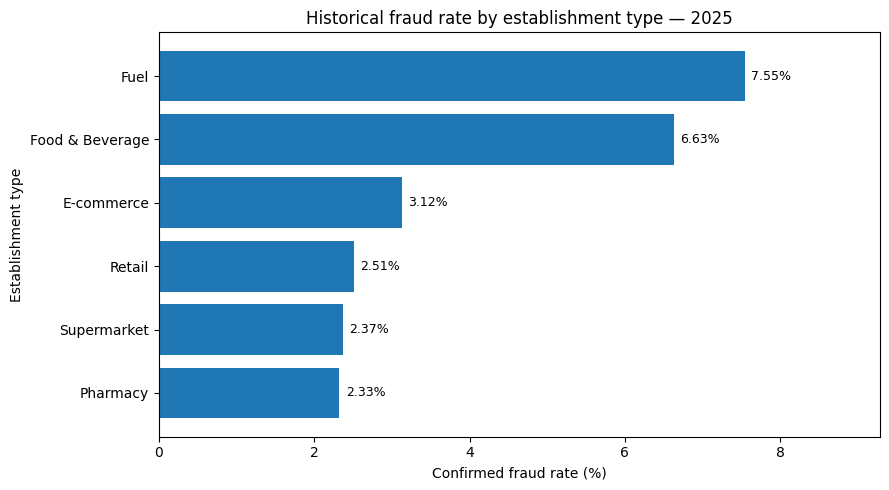

In [7]:
# Historical fraud rate by establishment type (descriptive, not causal)
plot_data = taxa_estabelecimento.sort_values("mean")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_data.index.astype(str), plot_data["mean"])
ax.set(xlabel="Confirmed fraud rate (%)", ylabel="Establishment type",
       title="Historical fraud rate by establishment type — 2025")
ax.set_xlim(left=0)
for pos, value in enumerate(plot_data["mean"]):
    ax.text(value + 0.08, pos, f"{value:.2f}%", va="center", fontsize=9)
ax.set_xlim(right=max(plot_data["mean"]) * 1.23)
plt.tight_layout()
plt.show()


**Key Findings:**

Fuel (7.55%) and Food & Beverage (6.63%) have the highest fraud rates, while Pharmacy has the lowest (2.33%).

These findings suggest that establishment type may be a relevant indicator for fraud detection.

### Fraud Analysis by Time of Day

**Research Question:** Are fraud rates different across periods of the day?

In [8]:

taxa_turno = (
    df.groupby("turno")["flag_fraude"]
    .agg(["count", "sum", "mean"])
)

taxa_turno["mean"] *= 100

taxa_turno = taxa_turno.sort_values(
    "mean", ascending=False
)

taxa_turno.round(2)

,count,sum,mean
turno,,,
noite,130876,13403,10.24
tarde,130871,4449,3.40
madrugada,130850,1764,1.35
manha,130928,869,0.66


**Key Findings:**

Night has the highest fraud rate (10.24%), followed by afternoon (3.40%), early morning (1.35%) and morning (0.66%).

### Hour-of-Day Fraud Patterns

**Research Question:** Are particular transaction hours associated with unusually high fraud rates, beyond the broad morning/afternoon/night categories?

,transactions,frauds,fraud_rate_pct
hour,,,
0,21799,291,1.33
1,21811,296,1.36
2,21810,320,1.47
3,21805,266,1.22
4,21811,304,1.39
5,21814,287,1.32
6,21819,274,1.26
7,21836,268,1.23
8,21820,327,1.50


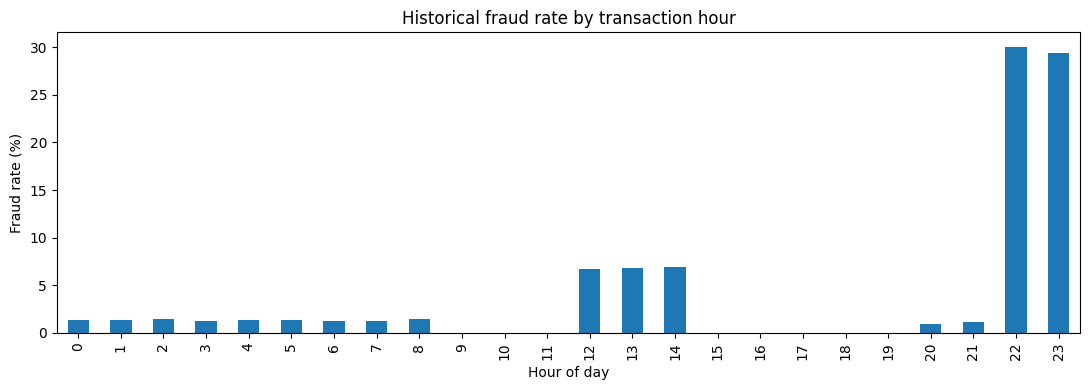

Highest-risk hour: 22
Peak historical fraud rate: 30.04%


In [9]:
# Explore hour-specific fraud rates using historical labels only.
df["datahora_transacao"] = pd.to_datetime(df["datahora_transacao"])
hourly_fraud = (df.assign(hour=df["datahora_transacao"].dt.hour)
                .groupby("hour")["flag_fraude"]
                .agg(transactions="size", frauds="sum", fraud_rate="mean"))
hourly_fraud["fraud_rate_pct"] = 100 * hourly_fraud["fraud_rate"]
display(hourly_fraud[["transactions", "frauds", "fraud_rate_pct"]].round(2))
ax = hourly_fraud["fraud_rate_pct"].plot(kind="bar", figsize=(11, 4), title="Historical fraud rate by transaction hour")
ax.set(xlabel="Hour of day", ylabel="Fraud rate (%)")
plt.tight_layout()
plt.show()
print("Highest-risk hour:", int(hourly_fraud["fraud_rate"].idxmax()))
print("Peak historical fraud rate: {:.2f}%".format(hourly_fraud["fraud_rate_pct"].max()))

**Key Findings:** Fraud is strongly concentrated in late-evening hours: **30.04% at 22:00** and **29.37% at 23:00**, compared with **6.71%–6.91% at 12:00–14:00** and **1.50% at 08:00**. The historical data show **0 observed frauds at 09:00–11:00 and 15:00–19:00** (each hour has more than 21,800 transactions). These striking time-of-day patterns help explain why adding transaction hour improves predictive performance. The observed associations should not be interpreted as causal effects.

## 2. Data Quality and Temporal Structure

**Research Question:** Are duplicate records present, and what time period does the dataset cover?

In [10]:
print("Duplicate records:", df.duplicated().sum())


# Parse transaction timestamps
df["datahora_transacao"] = pd.to_datetime(
    df["datahora_transacao"]
)

print("First transaction:")
print(df["datahora_transacao"].min())

print("\nLast transaction:")
print(df["datahora_transacao"].max())

print("\nTransactions by month:")
print(
    df["datahora_transacao"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

Duplicate records: 0
First transaction:
2025-01-01 00:00:00

Last transaction:
2025-12-31 23:59:00

Transactions by month:
datahora_transacao
2025-01    44463
2025-02    40162
2025-03    44473
2025-04    43028
2025-05    44464
2025-06    43022
2025-07    44464
2025-08    44448
2025-09    43042
2025-10    44468
2025-11    43040
2025-12    44451
Freq: M, Name: count, dtype: int64


**Key Findings:**

No duplicate records were identified. The historical dataset covers January through December 2025. A chronological split helps evaluate future-period performance.

## 3. Baseline Models — Validation Only

**Research Question:** Does Random Forest outperform Logistic Regression on the same chronological validation set?

Models are fitted on January–August 2025 and compared on September–October 2025. November–December is reserved for the final holdout assessment. The baseline comparison is exploratory; model and threshold selection must not use final test outcomes.


In [11]:

# Sort data chronologically
df = df.sort_values("datahora_transacao").copy()

treino = df[
    df["datahora_transacao"] < "2025-09-01"
].copy()

validacao = df[
    (df["datahora_transacao"] >= "2025-09-01") &
    (df["datahora_transacao"] < "2025-11-01")
].copy()

teste = df[
    df["datahora_transacao"] >= "2025-11-01"
].copy()

print("Training transactions:", len(treino))
print("Test transactions:", len(teste))



print(
    "Training fraud rate:",
    round(treino["flag_fraude"].mean() * 100, 2),
    "%"
)

print(
    "Test fraud rate:",
    round(teste["flag_fraude"].mean() * 100, 2),
    "%"
)



y_treino = treino["flag_fraude"]
y_teste = teste["flag_fraude"]

X_treino = treino.drop(
    columns=["flag_fraude"]
)

X_teste = teste.drop(
    columns=["flag_fraude"]
)

print("Training X:", X_treino.shape)
print("Test X:", X_teste.shape)

print("Training y:", y_treino.shape)
print("Test y:", y_teste.shape)
print("Validation transactions:", len(validacao))
print("Validation fraud rate:", round(validacao["flag_fraude"].mean()*100, 2), "%")
X_validacao = validacao.drop(columns=["flag_fraude"])
y_validacao = validacao["flag_fraude"]
print("Validation X:", X_validacao.shape)
print("Validation y:", y_validacao.shape)


Training transactions: 348524
Test transactions: 87491
Training fraud rate: 3.78 %
Test fraud rate: 4.56 %
Training X: (348524, 14)
Test X: (87491, 14)
Training y: (348524,)
Test y: (87491,)
Validation transactions: 87510
Validation fraud rate: 3.78 %
Validation X: (87510, 14)
Validation y: (87510,)


In [12]:

colunas_modelo = [
    "valor_transacao",
    "tipo_estabelecimento",
    "cidade",
    "device_type",
    "is_new_device",
    "temperatura_celsius",
    "score_interno",
    "turno",
    "valor_categoria",
    "cidade_regiao"
]

X_treino = treino[colunas_modelo].copy()
X_validacao = validacao[colunas_modelo].copy()
X_teste = teste[colunas_modelo].copy()

print("Training X:", X_treino.shape)
print("Test X:", X_teste.shape)
print("Validation X:", X_validacao.shape)

print("\nFeature data types:")
print(X_treino.dtypes)




colunas_numericas = [
    "valor_transacao",
    "temperatura_celsius",
    "score_interno"
]

colunas_categoricas = [
    "tipo_estabelecimento",
    "cidade",
    "device_type",
    "turno",
    "valor_categoria",
    "cidade_regiao"
]

preprocessador = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), colunas_numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         colunas_categoricas),
        ("bool", "passthrough", ["is_new_device"])
    ]
)

print("Preprocessor created successfully!")




# Create the model
modelo_logistico = Pipeline(
    steps=[
        ("preprocessamento", preprocessador),
        ("classificador", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

# Train the model
modelo_logistico.fit(X_treino, y_treino)

print("Model trained successfully!")

Training X: (348524, 10)
Test X: (87491, 10)
Validation X: (87510, 10)

Feature data types:
valor_transacao         float64
tipo_estabelecimento     object
cidade                   object
device_type              object
is_new_device              bool
temperatura_celsius     float64
score_interno             int64
turno                    object
valor_categoria          object
cidade_regiao            object
dtype: object
Preprocessor created successfully!
Model trained successfully!


Predictions generated successfully!
Number of predictions: 87510
Accuracy: 0.7857
Precision: 0.1295
Recall: 0.8164
F1-score: 0.2235


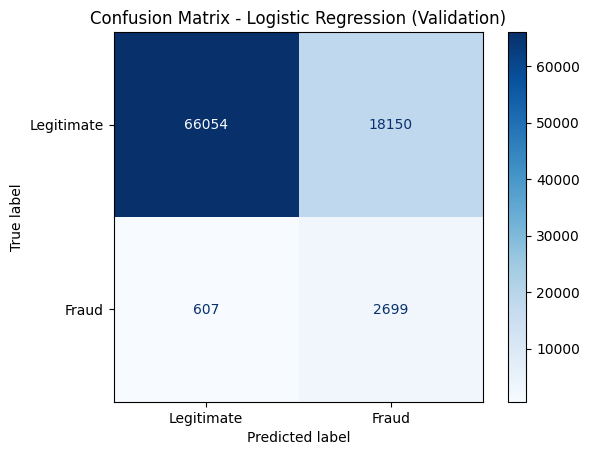

In [13]:

y_pred = modelo_logistico.predict(X_validacao)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))




print("Accuracy:",
      round(accuracy_score(y_validacao, y_pred), 4))

print("Precision:",
      round(precision_score(y_validacao, y_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_validacao, y_pred, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_validacao, y_pred, zero_division=0), 4))




matriz = confusion_matrix(y_validacao, y_pred)

# Visualize
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Legitimate", "Fraud"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Logistic Regression (Validation)")
plt.show()

In [14]:


# Create Random Forest model
modelo_rf = Pipeline(
    steps=[
        ("preprocessamento", preprocessador),
        ("classificador", RandomForestClassifier(
            n_estimators=100,
            max_depth=12,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train model
modelo_rf.fit(X_treino, y_treino)

print("Random Forest trained successfully!")



y_pred_rf = modelo_rf.predict(X_validacao)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred_rf))




print("Random Forest")

print("Accuracy:",
      round(accuracy_score(y_validacao, y_pred_rf), 4))

print("Precision:",
      round(precision_score(y_validacao, y_pred_rf), 4))

print("Recall:",
      round(recall_score(y_validacao, y_pred_rf), 4))

print("F1-score:",
      round(f1_score(y_validacao, y_pred_rf), 4))

Random Forest trained successfully!
Predictions generated successfully!
Number of predictions: 87510
Random Forest
Accuracy: 0.8269
Precision: 0.1723
Recall: 0.9416
F1-score: 0.2912


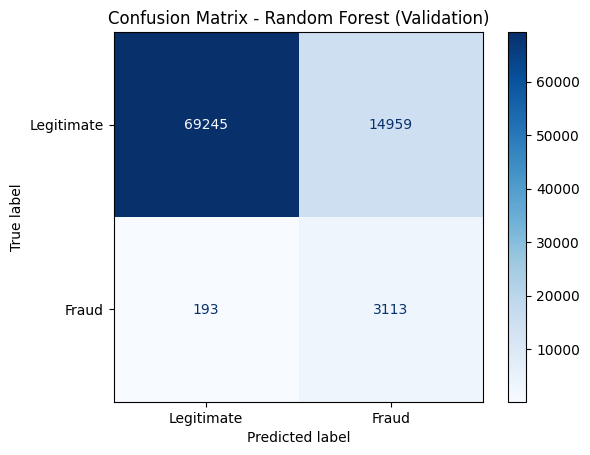

In [15]:


matriz_rf = confusion_matrix(y_validacao, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf,
    display_labels=["Legitimate", "Fraud"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Random Forest (Validation)")
plt.show()

**Baseline comparison — September–October 2025**

Both baseline models were fitted on January–August and evaluated on the same validation period. The comparison below uses their default `predict` decisions; it is **not** the final tuned-threshold comparison. November–December remains reserved for the final holdout.


In [16]:
# Side-by-side baseline comparison on the same chronological validation set.
baseline_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression (10 features)",
        "Accuracy": accuracy_score(y_validacao, y_pred),
        "Precision": precision_score(y_validacao, y_pred, zero_division=0),
        "Recall": recall_score(y_validacao, y_pred, zero_division=0),
        "F1-score": f1_score(y_validacao, y_pred, zero_division=0),
    },
    {
        "Model": "Random Forest (10 features)",
        "Accuracy": accuracy_score(y_validacao, y_pred_rf),
        "Precision": precision_score(y_validacao, y_pred_rf, zero_division=0),
        "Recall": recall_score(y_validacao, y_pred_rf, zero_division=0),
        "F1-score": f1_score(y_validacao, y_pred_rf, zero_division=0),
    }
])
display(baseline_comparison.style.format({
    "Accuracy": "{:.2%}", "Precision": "{:.2%}",
    "Recall": "{:.2%}", "F1-score": "{:.2%}"
}))
print("Comparison is descriptive: default prediction thresholds may differ in effective operating behavior.")


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression (10 features),78.57%,12.95%,81.64%,22.35%
1,Random Forest (10 features),82.69%,17.23%,94.16%,29.12%


Comparison is descriptive: default prediction thresholds may differ in effective operating behavior.


## 4. Temporal Validation and Initial Random Forest

**Research Question:** How does the 10-feature Random Forest perform on later transactions, and how do classification thresholds change false positives and missed fraud?

Train: January–August 2025; validation: September–October; final test: November–December (not used in the revised baseline comparison or threshold selection).

In [17]:
# Reuse the chronological partitions established in Section 3.
# Do not resplit the data or expose the holdout to model selection.
treino_final = treino
# `validacao` was already created in Section 3.
teste_final = teste

X_train_final = treino_final[colunas_modelo].copy()
X_val = validacao[colunas_modelo].copy()
X_test_final = teste_final[colunas_modelo].copy()
y_train_final = treino_final["flag_fraude"].copy()
y_val = validacao["flag_fraude"].copy()
y_test_final = teste_final["flag_fraude"].copy()

print("Training:", X_train_final.shape)
print("Validation:", X_val.shape)
print("Final holdout:", X_test_final.shape)
print("Fraud rates (%):", *(round(y.mean()*100, 2) for y in
                          [y_train_final, y_val, y_test_final]))

modelo_rf_final = clone(modelo_rf)

# Train on January–August only
modelo_rf_final.fit(X_train_final, y_train_final)

print("Random Forest trained successfully!")

Training: (348524, 10)
Validation: (87510, 10)
Final holdout: (87491, 10)
Fraud rates (%): 3.78 3.78 4.56
Random Forest trained successfully!


In [18]:

prob_val = modelo_rf_final.predict_proba(X_val)[:, 1]

print("Number of probabilities:", len(prob_val))
print("Minimum probability:", round(prob_val.min(), 4))
print("Maximum probability:", round(prob_val.max(), 4))
print("Mean probability:", round(prob_val.mean(), 4))




resultados = []

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:

    y_pred_val = prob_val >= threshold

    resultados.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_pred_val, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred_val, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, y_pred_val, zero_division=0
        ),
        "False positives": (
            (y_pred_val == 1) & (y_val == 0)
        ).sum()
    })

comparacao_threshold = pd.DataFrame(resultados)

comparacao_threshold.round(4)





Number of probabilities: 87510
Minimum probability: 0.0
Maximum probability: 0.969
Mean probability: 0.1957


,Threshold,Precision,Recall,F1-score,False positives
0,0.3,0.1472,0.9915,0.2564,18984
1,0.4,0.1562,0.9740,0.2692,17394
2,0.5,0.1723,0.9416,0.2912,14959
3,0.6,0.2067,0.8724,0.3343,11066
4,0.7,0.3011,0.6897,0.4192,5291
5,0.8,0.3853,0.5759,0.4617,3037


In [19]:
# Baseline ranking performance on the validation period (10 features).
ap_val_10 = average_precision_score(y_val, prob_val)
print(f"10-feature validation Average Precision: {ap_val_10:.4f}")
print(f"Validation fraud prevalence: {y_val.mean():.4f}")

10-feature validation Average Precision: 0.4309
Validation fraud prevalence: 0.0378


**Key Findings:** The 10-feature Random Forest achieved **0.4309 Average Precision** on the September–October validation period. This is the baseline against which the refined 12-feature model is compared using the same validation observations.

## 5. Time Features and Final Model Selection

**Research Question:** Do hour of day and day of week improve validation performance, and which threshold offers the best F1-score among the evaluated candidates?

The 10- and 12-feature models are compared on the same validation period. The final threshold is selected from validation results only. Without verified business costs, maximizing validation F1 is a transparent modeling choice, **not proof of the lowest operational cost**.

In [20]:

df["hora"] = df["datahora_transacao"].dt.hour
df["dia_semana"] = df["datahora_transacao"].dt.dayofweek

# Inspect results
display(df[["datahora_transacao", "hora", "dia_semana"]].head(10))


colunas_modelo_novo = X_train_final.columns.tolist().copy()

for coluna in ["hora", "dia_semana"]:
    if coluna not in colunas_modelo_novo:
        colunas_modelo_novo.append(coluna)

print("Refined model features:")
print(colunas_modelo_novo)

print("\nTotal:", len(colunas_modelo_novo))




treino_final["datahora_transacao"] = pd.to_datetime(
    treino_final["datahora_transacao"]
)

treino_final["hora"] = treino_final["datahora_transacao"].dt.hour

treino_final["dia_semana"] = treino_final["datahora_transacao"].dt.dayofweek

# Inspect new features
print(treino_final[["hora", "dia_semana"]].head())

print("\nNew features created successfully!")


,datahora_transacao,hora,dia_semana
0,2025-01-01 00:00:00,0,2
1,2025-01-01 00:01:00,0,2
2,2025-01-01 00:02:00,0,2
3,2025-01-01 00:03:00,0,2
4,2025-01-01 00:04:00,0,2
5,2025-01-01 00:05:00,0,2
6,2025-01-01 00:06:00,0,2
7,2025-01-01 00:07:00,0,2
8,2025-01-01 00:08:00,0,2
9,2025-01-01 00:09:00,0,2


Refined model features:
['valor_transacao', 'tipo_estabelecimento', 'cidade', 'device_type', 'is_new_device', 'temperatura_celsius', 'score_interno', 'turno', 'valor_categoria', 'cidade_regiao', 'hora', 'dia_semana']

Total: 12
   hora  dia_semana
0     0           2
1     0           2
2     0           2
3     0           2
4     0           2

New features created successfully!


In [21]:

# Prepare data for refined Random Forest

X_train_novo = treino_final[colunas_modelo_novo].copy()

y_train_novo = treino_final["flag_fraude"].copy()

print("Training dimensions:")
print(X_train_novo.shape)

print("\nNumber of features:", X_train_novo.shape[1])

print("\nClass distribution:")
print(y_train_novo.value_counts())




validacao["datahora_transacao"] = pd.to_datetime(
    validacao["datahora_transacao"]
)

validacao["hora"] = validacao["datahora_transacao"].dt.hour

validacao["dia_semana"] = validacao["datahora_transacao"].dt.dayofweek

X_val_novo = validacao[colunas_modelo_novo].copy()

y_val_novo = validacao["flag_fraude"].copy()

# Inspect results
print("Validation dimensions:", X_val_novo.shape)
print("Number of features:", X_val_novo.shape[1])

print("\nClass distribution:")
print(y_val_novo.value_counts())




colunas_categoricas_novo = (
    X_train_novo.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()
)

colunas_numericas_novo = [
    col for col in X_train_novo.columns
    if col not in colunas_categoricas_novo
]

print("Categorical features:")
print(colunas_categoricas_novo)

print("\nNumerical features:")
print(colunas_numericas_novo)

preprocessador_novo = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            colunas_categoricas_novo
        ),
        (
            "numericas",
            "passthrough",
            colunas_numericas_novo
        )
    ]
)

print("\nPreprocessing ready!")

Training dimensions:
(348524, 12)

Number of features: 12

Class distribution:
flag_fraude
False    335336
True      13188
Name: count, dtype: int64
Validation dimensions: (87510, 12)
Number of features: 12

Class distribution:
flag_fraude
False    84204
True      3306
Name: count, dtype: int64
Categorical features:
['tipo_estabelecimento', 'cidade', 'device_type', 'is_new_device', 'turno', 'valor_categoria', 'cidade_regiao']

Numerical features:
['valor_transacao', 'temperatura_celsius', 'score_interno', 'hora', 'dia_semana']

Preprocessing ready!


In [22]:



modelo_rf_novo = Pipeline(steps=[
    ("preprocessamento", preprocessador_novo),

    ("classificador", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
modelo_rf_novo.fit(X_train_novo, y_train_novo)

print("Random Forest trained successfully!")




# Compute fraud probabilities
prob_val_novo = modelo_rf_novo.predict_proba(X_val_novo)[:, 1]



Random Forest trained successfully!


In [23]:
# Compare the 10- and 12-feature models using the same validation observations.
ap_val_12 = average_precision_score(y_val_novo, prob_val_novo)
ap_comparison = pd.DataFrame({
    "Model": ["Random Forest: 10 features", "Random Forest: 12 features"],
    "Validation AP": [ap_val_10, ap_val_12],
})
display(ap_comparison.round(4))
print(f"Absolute AP improvement: {ap_val_12 - ap_val_10:+.4f}")
print(f"Relative AP improvement: {(ap_val_12 / ap_val_10 - 1) * 100:+.1f}%")

,Model,Validation AP
0,Random Forest: 10 features,0.4309
1,Random Forest: 12 features,0.6362


Absolute AP improvement: +0.2053
Relative AP improvement: +47.7%


### Threshold selection — validation only

Select the operating threshold using September–October validation labels before reporting any threshold-dependent model metrics.

In [24]:

# Compare thresholds for the refined Random Forest


resultados = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]:

    previsoes = (prob_val_novo >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_novo, previsoes
    ).ravel()

    resultados.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val_novo, previsoes, zero_division=0
        ),
        "Recall": recall_score(
            y_val_novo, previsoes, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_novo, previsoes, zero_division=0
        ),
        "False positives": fp,
        "False negatives": fn
    })

df_threshold_novo = pd.DataFrame(resultados)

display(df_threshold_novo.round(4))

# Select the decision threshold using validation data only.
# F1 is used as an explicit proxy objective because actual business costs are unavailable.
threshold_final_novo = float(df_threshold_novo.loc[df_threshold_novo["F1-score"].idxmax(), "Threshold"])
print(f"Selected validation threshold (highest F1 among candidates): {threshold_final_novo:.2f}")
print(df_threshold_novo.loc[df_threshold_novo["Threshold"] == threshold_final_novo].to_string(index=False))





,Threshold,Precision,Recall,F1-score,False positives,False negatives
0,0.3,0.3237,0.9973,0.4887,6889,9
1,0.4,0.3620,0.9940,0.5307,5792,20
2,0.5,0.3774,0.9900,0.5465,5399,33
3,0.6,0.3906,0.9794,0.5585,5051,68
4,0.7,0.4127,0.9407,0.5737,4426,196
5,0.8,0.4747,0.8282,0.6035,3030,568
6,0.9,0.7039,0.4882,0.5765,679,1692


Selected validation threshold (highest F1 among candidates): 0.80
 Threshold  Precision   Recall  F1-score  False positives  False negatives
       0.8   0.474688 0.828191  0.603482             3030              568


In [25]:
# Apply the threshold selected on validation data
y_pred_val_novo = (prob_val_novo >= threshold_final_novo).astype(int)

# Evaluate performance
print("REFINED RANDOM FOREST RESULTS")
print("-" * 40)

print("Accuracy:",
      round(accuracy_score(y_val_novo, y_pred_val_novo), 4))

print("Precision:",
      round(precision_score(y_val_novo, y_pred_val_novo,
                            zero_division=0), 4))

print("Recall:",
      round(recall_score(y_val_novo, y_pred_val_novo,
                         zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_val_novo, y_pred_val_novo,
                     zero_division=0), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_val_novo, y_pred_val_novo))




prob_original = modelo_rf_final.predict_proba(X_val)[:, 1]
pred_original = (prob_original >= threshold_final_novo).astype(int)

pred_novo = (prob_val_novo >= threshold_final_novo).astype(int)

comparacao = pd.DataFrame({
    "Model": ["Original (10 features)", "New (12 features)"],
    "Precision": [
        precision_score(y_val, pred_original, zero_division=0),
        precision_score(y_val_novo, pred_novo, zero_division=0)
    ],
    "Recall": [
        recall_score(y_val, pred_original, zero_division=0),
        recall_score(y_val_novo, pred_novo, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_val, pred_original, zero_division=0),
        f1_score(y_val_novo, pred_novo, zero_division=0)
    ]
})

display(comparacao.round(4))

REFINED RANDOM FOREST RESULTS
----------------------------------------
Accuracy: 0.9589
Precision: 0.4747
Recall: 0.8282
F1-score: 0.6035

Confusion matrix:
[[81174  3030]
 [  568  2738]]


,Model,Precision,Recall,F1-score
0,Original (10 features),0.3853,0.5759,0.4617
1,New (12 features),0.4747,0.8282,0.6035


### Precision–Recall curve — validation

The curve summarizes precision and recall across decision thresholds. The marked point corresponds to the threshold chosen by validation F1. The dashed line is validation fraud prevalence.

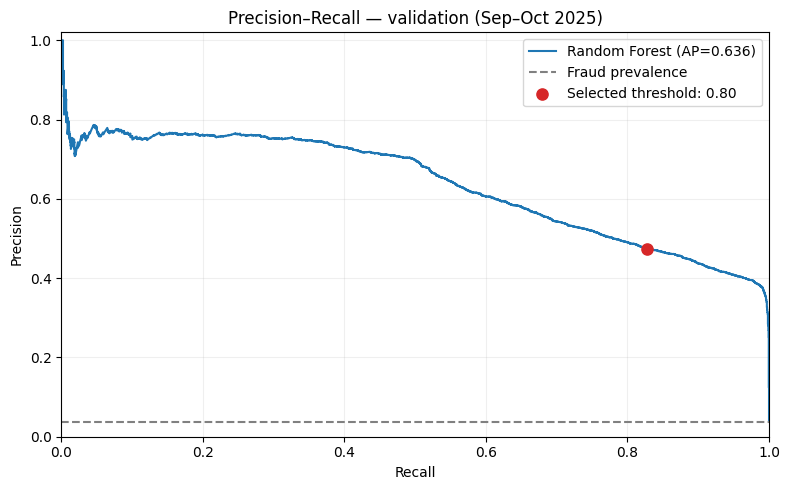

In [26]:
# Precision–Recall curve for the 12-feature model (validation only)
precision_curve, recall_curve, _ = precision_recall_curve(y_val_novo, prob_val_novo)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(recall_curve, precision_curve, label=f"Random Forest (AP={ap_val_12:.3f})")
ax.axhline(y_val_novo.mean(), color="gray", linestyle="--", label="Fraud prevalence")
ax.scatter(
    recall_score(y_val_novo, (prob_val_novo >= threshold_final_novo).astype(int)),
    precision_score(y_val_novo, (prob_val_novo >= threshold_final_novo).astype(int), zero_division=0),
    color="tab:red", s=65, zorder=3, label=f"Selected threshold: {threshold_final_novo:.2f}"
)
ax.set(xlabel="Recall", ylabel="Precision", title="Precision–Recall — validation (Sep–Oct 2025)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### Final holdout — November–December 2025

Apply the previously selected threshold once to the chronological holdout. Do not tune it using these results.

In [27]:
# Prepare final test set

teste_final["datahora_transacao"] = pd.to_datetime(
    teste_final["datahora_transacao"]
)

teste_final["hora"] = (
    teste_final["datahora_transacao"].dt.hour
)

teste_final["dia_semana"] = (
    teste_final["datahora_transacao"].dt.dayofweek
)

X_test_novo = teste_final[colunas_modelo_novo].copy()

y_test_novo = teste_final["flag_fraude"].copy()

print("Test dimensions:", X_test_novo.shape)
print("Number of features:", X_test_novo.shape[1])

print("\nClass distribution:")
print(y_test_novo.value_counts())





# Compute test probabilities
prob_test_novo = modelo_rf_novo.predict_proba(
    X_test_novo
)[:, 1]

resultados_teste = []

for threshold in [threshold_final_novo]:

    previsoes = (
        prob_test_novo >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_novo, previsoes,
        labels=[0, 1]
    ).ravel()

    resultados_teste.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test_novo, previsoes,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_novo, previsoes,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_test_novo, previsoes,
            zero_division=0
        ),
        "Frauds detected": tp,
        "False positives": fp,
        "Missed frauds": fn
    })

df_resultados_teste = pd.DataFrame(
    resultados_teste
)

display(df_resultados_teste.round(4))

print("\nSelected threshold (chosen before testing):", threshold_final_novo)
print("Final holdout results at the selected threshold:")
display(df_resultados_teste.loc[np.isclose(df_resultados_teste["Threshold"], threshold_final_novo)].round(4))

Test dimensions: (87491, 12)
Number of features: 12

Class distribution:
flag_fraude
False    83500
True      3991
Name: count, dtype: int64


,Threshold,Precision,Recall,F1-score,Frauds detected,False positives,Missed frauds
0,0.8,0.5064,0.7442,0.6027,2970,2895,1021



Selected threshold (chosen before testing): 0.8
Final holdout results at the selected threshold:


,Threshold,Precision,Recall,F1-score,Frauds detected,False positives,Missed frauds
0,0.8,0.5064,0.7442,0.6027,2970,2895,1021


In [28]:
# Final holdout metrics at the validation-selected threshold (do not reselect on test).
selected_test_predictions = (prob_test_novo >= threshold_final_novo).astype(int)
final_metrics = {
    "Threshold": threshold_final_novo,
    "Test AP": average_precision_score(y_test_novo, prob_test_novo),
    "Test precision": precision_score(y_test_novo, selected_test_predictions, zero_division=0),
    "Test recall": recall_score(y_test_novo, selected_test_predictions, zero_division=0),
    "Test F1": f1_score(y_test_novo, selected_test_predictions, zero_division=0),
}
display(pd.DataFrame([final_metrics]).round(4))
print("Final result: threshold {Threshold:.2f}; test AP {Test AP:.3f}; precision {Test precision:.3f}; recall {Test recall:.3f}; F1 {Test F1:.3f}.".format(**final_metrics))

,Threshold,Test AP,Test precision,Test recall,Test F1
0,0.8,0.6164,0.5064,0.7442,0.6027


Final result: threshold 0.80; test AP 0.616; precision 0.506; recall 0.744; F1 0.603.


### Threshold Selection and Business Trade-offs

**Research Question:** How much fraud detection would be gained by lowering the alert threshold, and what additional false-positive workload would that create? The threshold is chosen **only on validation data**. The test set is used afterward for reporting, not for selecting a different threshold.

In [29]:
# Validation trade-off at two illustrative operating points.
operating_points = df_threshold_novo.loc[df_threshold_novo["Threshold"].isin([0.50, 0.80]),
    ["Threshold", "Precision", "Recall", "F1-score", "False positives", "False negatives"]].copy()
operating_points.columns = ["Threshold", "Precision", "Recall", "F1", "False positives", "Missed frauds"]
display(operating_points.round(4))
print(f"Selected validation threshold: {threshold_final_novo:.2f}")
print("Selection rule: highest validation F1 among the pre-specified candidate thresholds.")
print("Business costs and review capacity were not provided; this is not a cost-optimal claim.")

,Threshold,Precision,Recall,F1,False positives,Missed frauds
2,0.5,0.3774,0.9900,0.5465,5399,33
5,0.8,0.4747,0.8282,0.6035,3030,568


Selected validation threshold: 0.80
Selection rule: highest validation F1 among the pre-specified candidate thresholds.
Business costs and review capacity were not provided; this is not a cost-optimal claim.


**Key Findings — Validation Threshold Selection:** Among the **seven thresholds evaluated** on September–October validation data, **0.80** produced the highest observed F1-score (**0.6035**), with **0.4747 precision**, **0.8282 recall**, **3,030 false positives**, and **568 missed frauds**. At **0.50**, recall rose to **0.9900**, while precision fell to **0.3774**, generating **5,399 false positives** and **33 missed frauds**.

**Interpretation:** The threshold of 0.80 is a **validation-selected F1 optimum among the tested candidates**, not a proven global optimum or a cost-optimal operating point. Because fraud losses, review costs, customer friction, and investigator capacity were not provided, it is best viewed as a **provisional operational starting point**. The trade-off should be reassessed using real costs and new confirmed labels.


### Final Model Feature Importance

**Research Question:** Which input features most influence the **12-feature Random Forest**, rather than the earlier 10-feature baseline?

,Feature,AP decrease when shuffled
10,hora,0.4583
7,turno,0.2482
1,tipo_estabelecimento,0.2209
4,is_new_device,0.1800
0,valor_transacao,0.1024
9,cidade_regiao,0.0708
2,cidade,0.0619
8,valor_categoria,0.0275
3,device_type,0.0114
11,dia_semana,0.0039


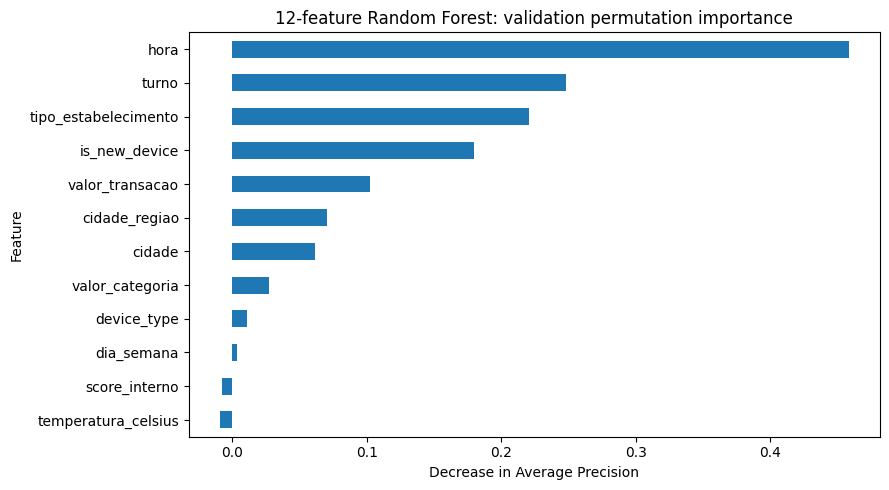

In [30]:
# Permutation importance on a reproducible validation subsample, using the final 12-feature model.
sample_size = min(10000, len(X_val_novo))
X_imp = X_val_novo.sample(n=sample_size, random_state=42)
y_imp = y_val_novo.loc[X_imp.index]
perm_final = permutation_importance(
    modelo_rf_novo, X_imp, y_imp, scoring="average_precision",
    n_repeats=2, random_state=42, n_jobs=2
)
feature_importance_final = (pd.DataFrame({
    "Feature": X_imp.columns,
    "AP decrease when shuffled": perm_final.importances_mean
}).sort_values("AP decrease when shuffled", ascending=False))
display(feature_importance_final.round(4))
ax = feature_importance_final.sort_values("AP decrease when shuffled").plot.barh(
    x="Feature", y="AP decrease when shuffled", legend=False, figsize=(9, 5),
    title="12-feature Random Forest: validation permutation importance")
ax.set_xlabel("Decrease in Average Precision")
plt.tight_layout()
plt.show()

### Temporal stability diagnostic — hour-of-day fraud patterns

**Research Question:** Is the association between late-evening hours and observed fraud similar across the historical months? The following descriptive analysis reports fraud prevalence at 22:00–23:00 versus all other hours by month, with transaction counts. Small monthly groups should be interpreted cautiously. This is a **descriptive stability check**, not a causal test or a recalculation of permutation importance.


,month,period,transactions,frauds,fraud_rate
0,2025-01,Other hours,40763,586,1.44%
1,2025-01,22:00–23:00,3700,1073,29.00%
2,2025-02,Other hours,36816,545,1.48%
3,2025-02,22:00–23:00,3346,939,28.06%
4,2025-03,Other hours,40767,589,1.44%
5,2025-03,22:00–23:00,3706,1102,29.74%
6,2025-04,Other hours,39439,607,1.54%
7,2025-04,22:00–23:00,3589,1037,28.89%
8,2025-05,Other hours,40760,573,1.41%
9,2025-05,22:00–23:00,3704,1070,28.89%


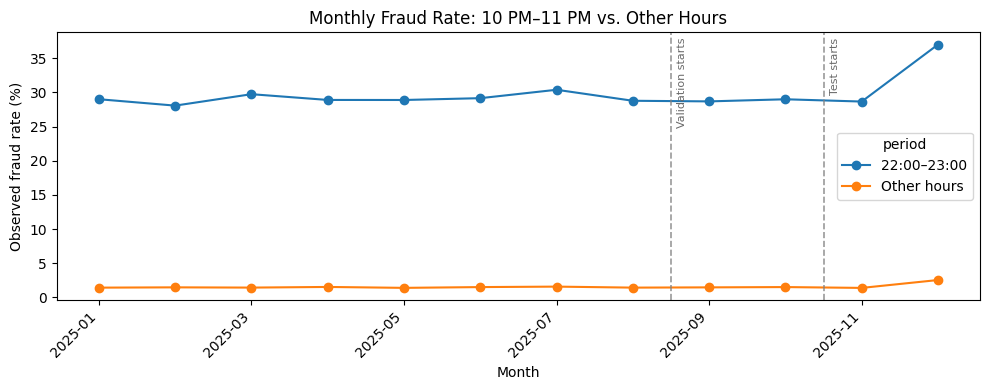

In [31]:
# Monthly descriptive check of the hour-of-day signal; no model refitting.
hour_stability = df[["datahora_transacao", "flag_fraude"]].copy()
hour_stability["month"] = hour_stability["datahora_transacao"].dt.to_period("M").astype(str)
hour_stability["late_evening"] = hour_stability["datahora_transacao"].dt.hour.isin([22, 23])
monthly_hour_rates = (hour_stability.groupby(["month", "late_evening"])["flag_fraude"]
                      .agg(transactions="size", frauds="sum", fraud_rate="mean")
                      .reset_index())
monthly_hour_rates["period"] = monthly_hour_rates["late_evening"].map({True: "22:00–23:00", False: "Other hours"})
display(monthly_hour_rates[["month", "period", "transactions", "frauds", "fraud_rate"]]
        .style.format({"fraud_rate": "{:.2%}"}))
monthly_pivot = monthly_hour_rates.pivot(index="month", columns="period", values="fraud_rate")
ax = (100 * monthly_pivot).plot(marker="o", figsize=(10, 4), title="Monthly Fraud Rate: 10 PM–11 PM vs. Other Hours")
# Temporal boundaries: train (Jan–Aug), validation (Sep–Oct), test (Nov–Dec).
# Monthly categories are plotted at integer positions 0, 1, ..., 11.
months = list(monthly_pivot.index)
for boundary_month, label in [("2025-09", "Validation starts"), ("2025-11", "Test starts")]:
    if boundary_month in months:
        boundary_x = months.index(boundary_month) - 0.5
        ax.axvline(boundary_x, color="gray", linestyle="--", linewidth=1.2, alpha=0.8)
        ax.text(boundary_x + 0.08, 0.98, label, rotation=90,
                transform=ax.get_xaxis_transform(), va="top", ha="left",
                fontsize=8, color="dimgray")
ax.set_ylabel("Observed fraud rate (%)")
ax.set_xlabel("Month")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Key Findings — Feature Importance:** On a sampled validation set, permutation importance ranked **transaction hour (AP decrease 0.4583)**, **time-of-day category (0.2482)**, **establishment type (0.2209)**, and **new-device status (0.1800)** highest. The large drop for `hora` indicates strong predictive reliance **in this validation sample**, not a causal effect. `hora` and `turno` are related, so their individual permutation importances should not be interpreted as independent contributions. The result uses two permutation repeats and a sample of up to 10,000 records; its uncertainty and temporal stability have not yet been established.

The monthly diagnostic below checks whether late-evening fraud concentration is consistent over time. It does **not**, by itself, establish month-by-month model feature importance.


**Key Findings — Model Improvement and Holdout Performance:** Adding transaction hour and weekday increased validation Average Precision from **0.4309 to 0.6362**, a gain of **0.2053** (**47.7% relative improvement**) on the same validation period. At the validation-selected threshold of **0.80**, the 12-feature Random Forest achieved **0.6164 test Average Precision**, **0.5064 precision**, **0.7442 recall** and **0.6027 F1-score** on November–December transactions. It detected **2,970 frauds**, with **2,895 false positives** and **1,021 missed frauds**.

### November–December Fraud Trend

**Research Question:** Did the confirmed fraud rate change in the final holdout months? This provides context for January predictions, but January alerts are not confirmed fraud.

In [32]:
monthly_test_fraud = (teste_final.assign(month=teste_final["datahora_transacao"].dt.to_period("M").astype(str))
                      .groupby("month")["flag_fraude"]
                      .agg(transactions="size", confirmed_frauds="sum", fraud_rate="mean"))
monthly_test_fraud["fraud_rate_pct"] = 100 * monthly_test_fraud["fraud_rate"]
display(monthly_test_fraud[["transactions", "confirmed_frauds", "fraud_rate_pct"]].round(2))

,transactions,confirmed_frauds,fraud_rate_pct
month,,,
2025-11,43040,1580,3.67
2025-12,44451,2411,5.42


**Key Findings:** Confirmed fraud prevalence increased from **3.67% in November** (**1,580 of 43,040 transactions**) to **5.42% in December** (**2,411 of 44,451 transactions**). This increase in the labeled holdout period motivates monitoring for changes in transaction risk, but it does not establish the true fraud rate in unlabeled January data.

## 6. Final Training and January 2026 Predictions

**Research Question:** How can the selected model score unseen transactions from January 2026?

In [33]:

# Load January 2026 transactions
df_jan = pd.read_csv("/content/transacoes_jan2026.csv")

print("Shape:", df_jan.shape)
print("\nColumn data types:")
print(df_jan.dtypes)

print("\nMissing values:")
print(df_jan.isnull().sum())




df_2025 = df.copy()

df_2025["datahora_transacao"] = pd.to_datetime(
    df_2025["datahora_transacao"]
)

df_2025 = df_2025[
    (df_2025["datahora_transacao"] >= "2025-01-01")
    & (df_2025["datahora_transacao"] < "2026-01-01")
].copy()

df_2025["hora"] = df_2025["datahora_transacao"].dt.hour

df_2025["dia_semana"] = (
    df_2025["datahora_transacao"].dt.dayofweek
)

# Prepare full training set
X_2025 = df_2025[colunas_modelo_novo].copy()

y_2025 = df_2025["flag_fraude"].copy()

print("2025 transactions:", len(X_2025))
print("Number of features:", X_2025.shape[1])

print("\nClass distribution:")
print(y_2025.value_counts())





# Clone the refined model
modelo_rf_2025 = clone(modelo_rf_novo)

# Fit on all 2025 data
modelo_rf_2025.fit(X_2025, y_2025)

print("Final Random Forest trained successfully!")

print("Training transactions:", len(X_2025))
print("Features used:", X_2025.shape[1])

Shape: (44451, 14)

Column data types:
datahora_transacao       object
nome_estabelecimento     object
tipo_estabelecimento     object
valor_transacao         float64
nome_cliente             object
cidade                   object
device_type              object
is_new_device              bool
temperatura_celsius     float64
codigo_postal            object
score_interno             int64
turno                    object
valor_categoria          object
cidade_regiao            object
dtype: object

Missing values:
datahora_transacao      0
nome_estabelecimento    0
tipo_estabelecimento    0
valor_transacao         0
nome_cliente            0
cidade                  0
device_type             0
is_new_device           0
temperatura_celsius     0
codigo_postal           0
score_interno           0
turno                   0
valor_categoria         0
cidade_regiao           0
dtype: int64
2025 transactions: 523525
Number of features: 12

Class distribution:
flag_fraude
False    503040
True   

In [34]:

# Prepare January 2026

df_jan_novo = df_jan.copy()

# Parse dates
df_jan_novo["datahora_transacao"] = pd.to_datetime(
    df_jan_novo["datahora_transacao"]
)

df_jan_novo["hora"] = (
    df_jan_novo["datahora_transacao"].dt.hour
)

df_jan_novo["dia_semana"] = (
    df_jan_novo["datahora_transacao"].dt.dayofweek
)

faltantes = [
    coluna for coluna in colunas_modelo_novo
    if coluna not in df_jan_novo.columns
]

print("Missing features:", faltantes)

print("Total transactions:", len(df_jan_novo))

print("\nNew features:")
display(
    df_jan_novo[
        ["datahora_transacao", "hora", "dia_semana"]
    ].head()
)




X_jan_novo = df_jan_novo[colunas_modelo_novo].copy()

# Compute fraud score
prob_jan_novo = modelo_rf_2025.predict_proba(
    X_jan_novo
)[:, 1]

# threshold_final_novo was selected using validation results in Section 5

previsoes_jan_novo = (
    prob_jan_novo >= threshold_final_novo
).astype(int)

# Preserve original transaction columns
resultado_jan_novo = df_jan.copy()

resultado_jan_novo["probabilidade_fraude"] = prob_jan_novo
resultado_jan_novo["flag_fraude"] = previsoes_jan_novo

print("Total transactions:", len(resultado_jan_novo))

print("\nPredicted transaction classes:")
print(resultado_jan_novo["flag_fraude"].value_counts())

print("\nFirst classified transactions:")
display(resultado_jan_novo.head())


# Export the required January 2026 dataset with the predicted flag_fraude.
# Preserve the original column order and add only the required label.

arquivo_csv = Path("/content/transacoes_jan2026_classificadas.csv")
resultado_entrega = df_jan.copy()
resultado_entrega["flag_fraude"] = previsoes_jan_novo.astype(int)
assert len(resultado_entrega) == len(df_jan)
assert resultado_entrega["flag_fraude"].isin([0, 1]).all()
assert "flag_fraude" in resultado_entrega.columns
resultado_entrega.to_csv(arquivo_csv, index=False, encoding="utf-8-sig")

quantidade_alertas = int(resultado_entrega["flag_fraude"].sum())
percentual_alertas = 100 * quantidade_alertas / len(resultado_entrega)
print(f"Saved: {arquivo_csv}")
print(f"Transactions: {len(resultado_entrega):,}")
print(f"Predicted fraud alerts: {quantidade_alertas:,} ({percentual_alertas:.2f}%)")
print(f"Model features: {len(colunas_modelo_novo)} | Threshold: {threshold_final_novo:.2f}")

# Optional Colab download:
# from google.colab import files
# files.download(str(arquivo_csv))

Missing features: []
Total transactions: 44451

New features:


,datahora_transacao,hora,dia_semana
0,2026-01-01 00:00:00,0,3
1,2026-01-01 00:01:00,0,3
2,2026-01-01 00:02:00,0,3
3,2026-01-01 00:03:00,0,3
4,2026-01-01 00:04:00,0,3


Total transactions: 44451

Predicted transaction classes:
flag_fraude
0    41283
1     3168
Name: count, dtype: int64

First classified transactions:


,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao,probabilidade_fraude,flag_fraude
0,2026-01-01 00:00:00,Pharmacy Z,Pharmacy,21.72,Cliente_16241,Curitiba,desktop,False,17.4,36135-417,691,madrugada,baixo,Sul,0.004597,0
1,2026-01-01 00:01:00,Electronics Store,Retail,28.70,Cliente_10027,Porto Alegre,mobile,False,11.9,83134-620,292,madrugada,baixo,Sul,0.003620,0
2,2026-01-01 00:02:00,Restaurant X,Food & Beverage,34.55,Cliente_13606,Porto Alegre,desktop,False,15.0,41309-759,81,madrugada,medio,Sul,0.006502,0
3,2026-01-01 00:03:00,Gas Station,Fuel,57.53,Cliente_7302,Belo Horizonte,desktop,False,23.5,15793-404,54,madrugada,medio,Sudeste,0.194752,0
4,2026-01-01 00:04:00,Gas Station,Fuel,149.50,Cliente_20061,Recife,desktop,False,28.1,73917-730,31,madrugada,alto,Nordeste,0.006374,0


Saved: /content/transacoes_jan2026_classificadas.csv
Transactions: 44,451
Predicted fraud alerts: 3,168 (7.13%)
Model features: 12 | Threshold: 0.80


In [35]:
# January alert rate is not an observed fraud rate: January has no confirmed labels.
alert_count = int(resultado_entrega["flag_fraude"].sum())
alert_rate = 100 * resultado_entrega["flag_fraude"].mean()
historical_rate = 100 * df_2025["flag_fraude"].mean()
print(f"January 2026 model alerts: {alert_count:,} / {len(resultado_entrega):,} ({alert_rate:.2f}%)")
print(f"Historical 2025 confirmed fraud prevalence: {historical_rate:.2f}%")
print("These percentages are not directly comparable as confirmed fraud rates.")

January 2026 model alerts: 3,168 / 44,451 (7.13%)
Historical 2025 confirmed fraud prevalence: 3.91%
These percentages are not directly comparable as confirmed fraud rates.


**Key Findings:** The final 12-feature Random Forest flagged **3,168 of 44,451 January 2026 transactions (7.13%)** using the validation-selected **0.80 threshold** after retraining on all labeled 2025 transactions. These are **predicted alerts, not confirmed fraud cases**. The 7.13% alert rate cannot be interpreted as an increase from the **3.91% confirmed historical fraud rate**, because the two percentages measure different outcomes.

## 7. Final Recommendation and Business Implications

Based on the experimental results, I recommend the **12-feature Random Forest model with a classification threshold of 0.80** as the initial fraud detection solution.

Adding the temporal features improved validation Average Precision (AP) from approximately 0.43 to 0.64. On the final test set, the model achieved a precision of 0.51, recall of 0.74, and AP of 0.62. The model generated 2,895 false positives while correctly detecting 2,970 fraudulent transactions, representing approximately one false alert for every detected fraud. This investigation workload must be evaluated against the available review capacity.

The threshold of 0.80 achieved the highest F1-score among the seven thresholds evaluated on the validation set. A threshold of 0.50 remains an alternative when prioritizing fraud detection coverage over reducing false positives. The final operational choice should consider investigation capacity, false-positive costs, and potential financial losses, which were not provided in the dataset.

The monthly analysis indicates that fraud rates for transactions occurring between **10 PM and 11 PM** remained approximately between 28% and 30% from January to November 2025, increasing to 37.0% in December. Fraud rates at other hours also increased, ranging from approximately 1.4% to 1.6% before December and reaching 2.55% in December. Since these late-evening transactions continued to represent approximately 8.3% of total transactions, the December increase suggests a change in fraud rates rather than a substantial change in transaction-hour composition.

Precision increased from approximately 0.47 in validation to 0.51 in testing, while fraud prevalence increased from 3.78% to 4.56%. This prevalence difference may partially explain the improvement in precision and should not be interpreted as evidence of better generalization.

For January 2026, the model may experience **lower recall if fraud patterns resemble those observed in December**, particularly because much of the training data comes from months with lower fraud prevalence. Monitoring recent fraud patterns and retraining with newly labeled transactions are therefore important.

Finally, `nome_cliente` and `codigo_postal` were excluded from the modeling features, and January 2026 transactions have no available fraud labels. Consequently, the model's performance on January transactions cannot yet be verified.

Overall, the recommended model provides a practical starting point for fraud detection, with future improvements guided by operational costs, newly labeled data, and changes in fraud behavior over time.